## APRENDIZAJE NO SUPERVISADO

En esta última parte del proyecto se va a utilizar el aprendizaje no supervisado con la intención de descubrir perfiles de estudiantes e interpretar como estos se relacionan con abandono, permanencia o graduación.

In [75]:
# Importación de librerías
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np
import random


## 1. Limpieza y selección de datos

Para esta primera parte del estudio vamos a importar los datos, limpiarlos y estandarizarlos para más tarde crear el modelo.

In [76]:
df = pd.read_csv("../rendimiento_estudiantes_limpio.csv")
print(df.columns)
col_cat = df.select_dtypes(include=["object", "category"]).columns.to_list()
col_num = df.select_dtypes(include=["int64", "float64"]).columns.to_list()

Index(['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso',
       'asistencia_diurna_vespertina', 'cualificacion_previa',
       'nota_cualificacion_previa', 'cualificacion_madre',
       'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre',
       'nota_admision', 'desplazado', 'necesidades_educativas_especiales',
       'deudor', 'matricula_al_dia', 'genero', 'becado',
       'edad_al_matricularse', 'internacional',
       'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas',
       'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas',
       'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion',
       'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas',
       'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas',
       'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo',
       'tasa_inflacion', 'pib', 'objetivo'],
      dtype='object')


## 2. Explorción y selección de los datos

A continuación se realiza un análisis de los datos para a continuación hacer la selección de las variables que se van a utilizar en el modelo

### 2.1. Exploración

**`Frecuencia de las variables categóricas`**

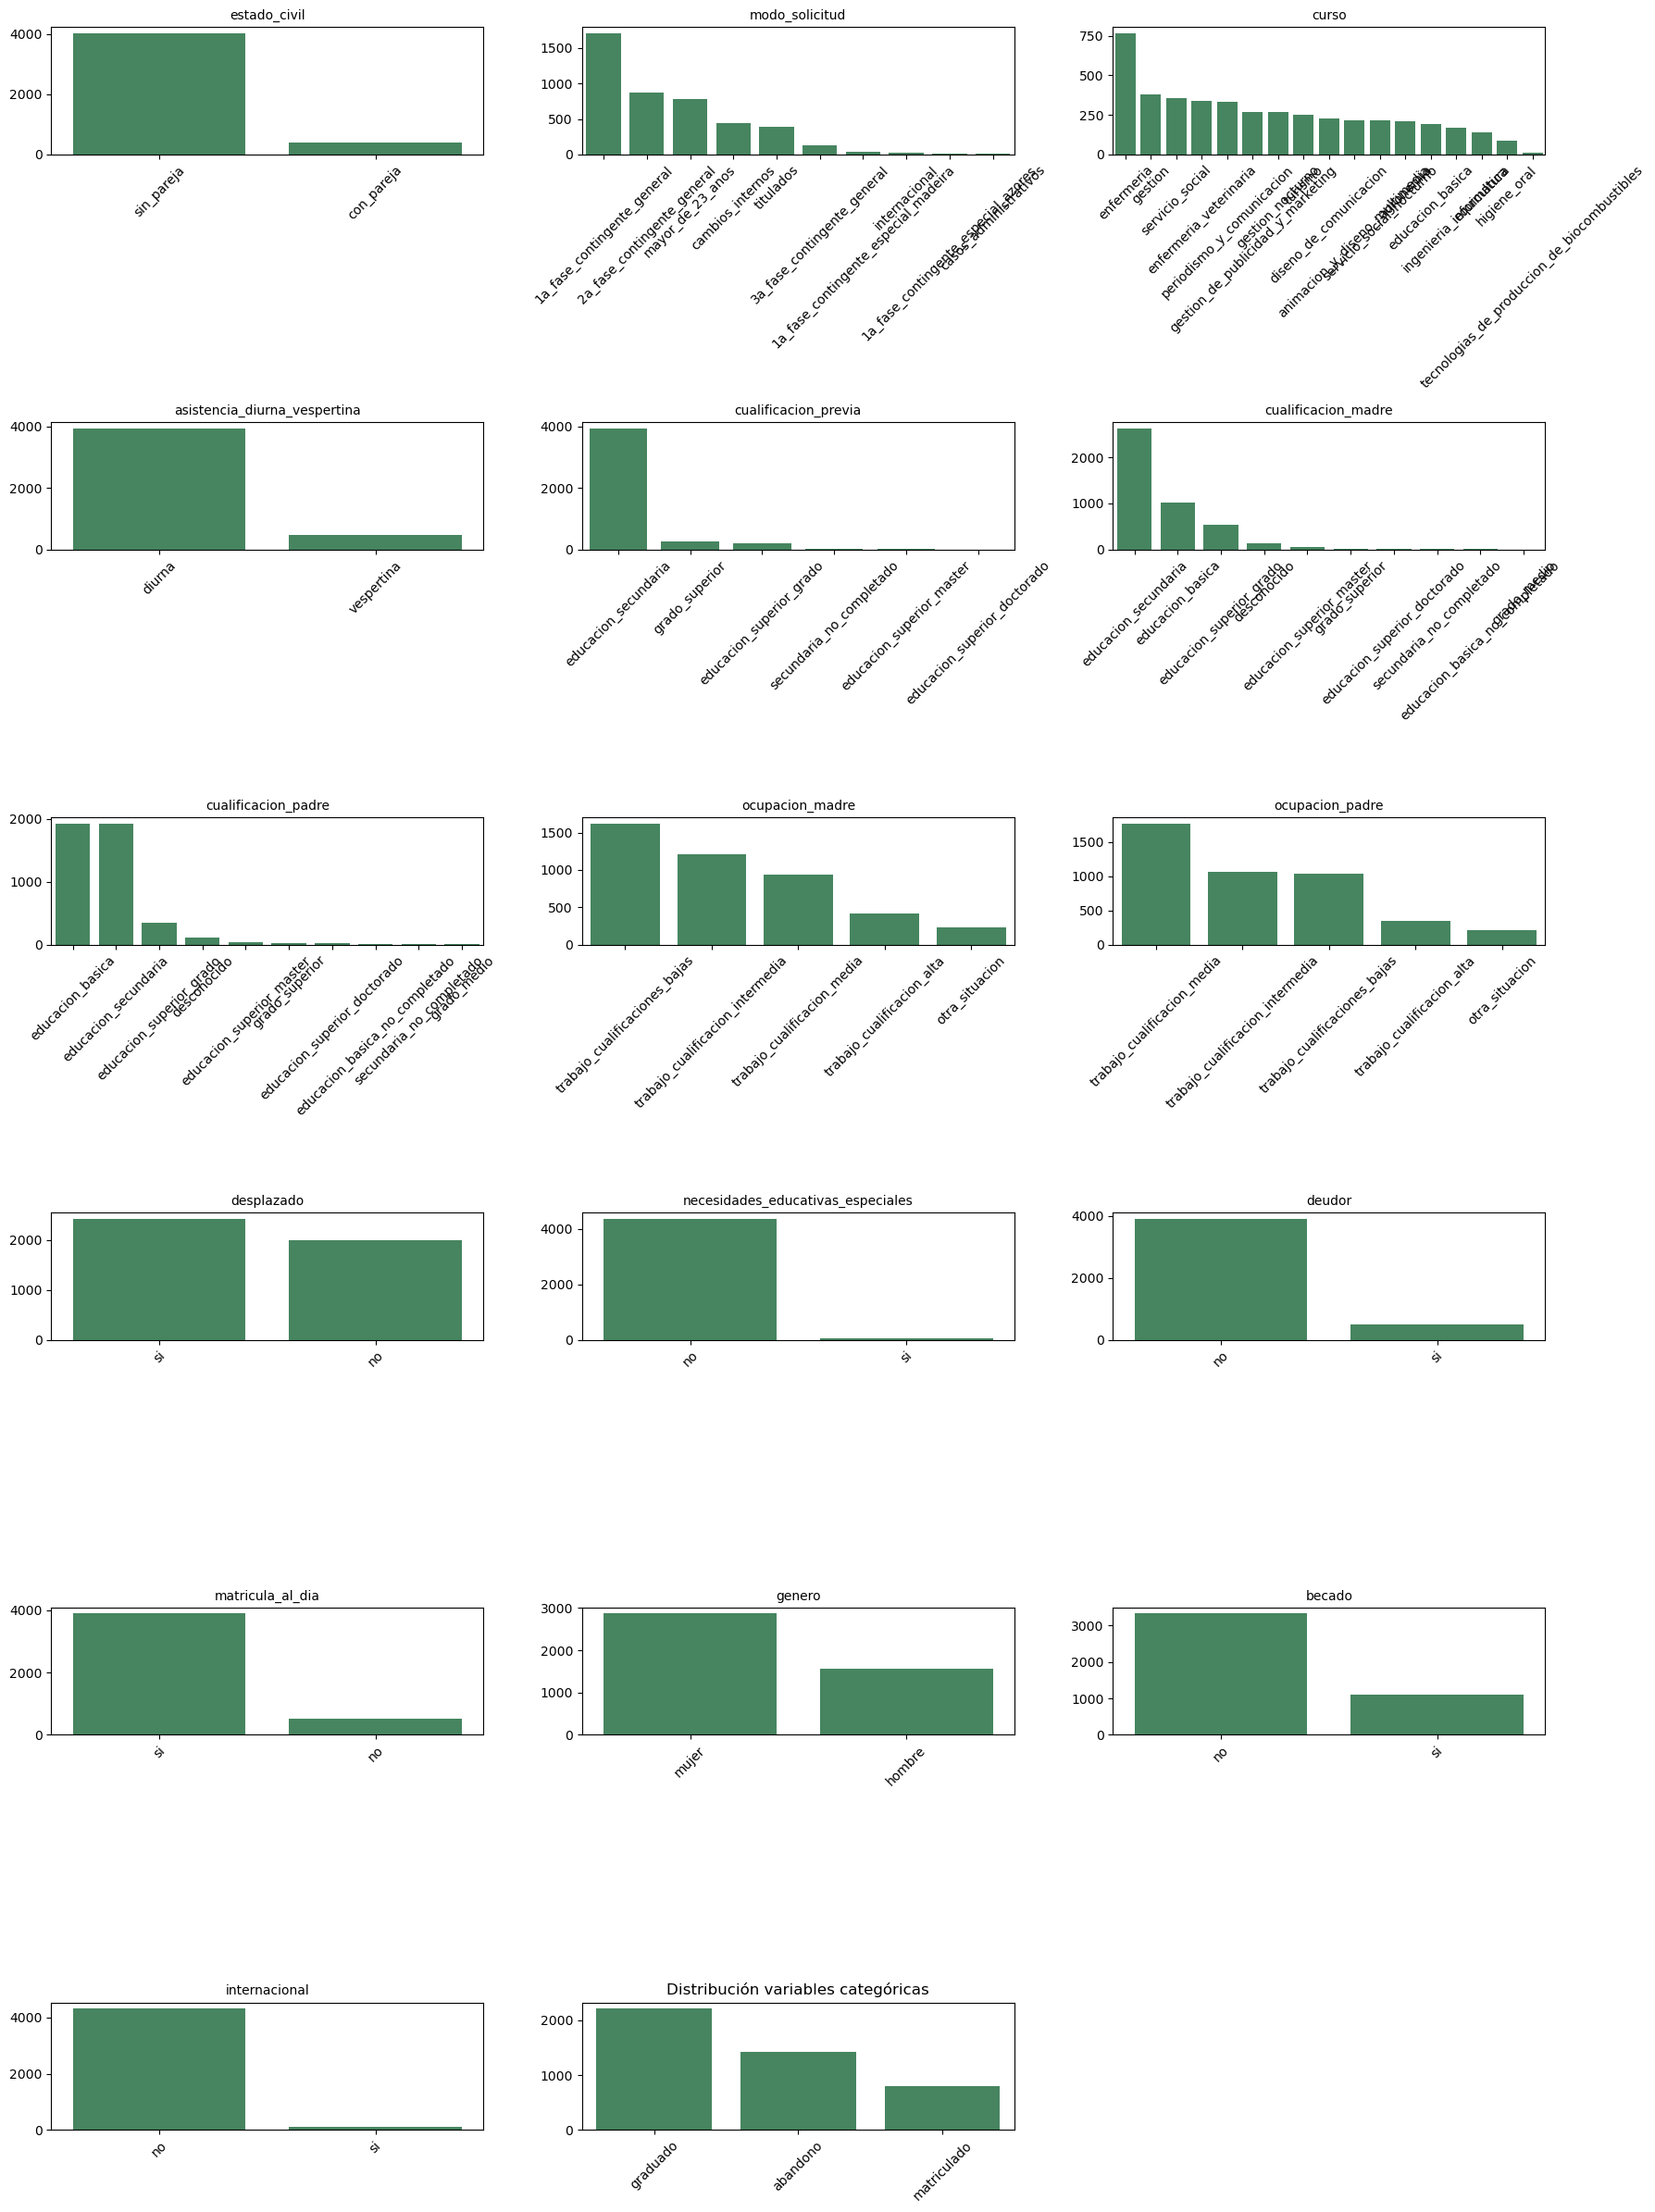

In [77]:
# Mostrar frecuencias de variables categóricas
n_cols = 3  # número de columnas en la cuadrícula
n_rows = math.ceil(len(col_cat) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_cat):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i], color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# borrar ejes vacíos si sobran
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.title('Distribución variables categóricas')
plt.tight_layout()
plt.show()

**`Frecuencia de las variables numéricas`**

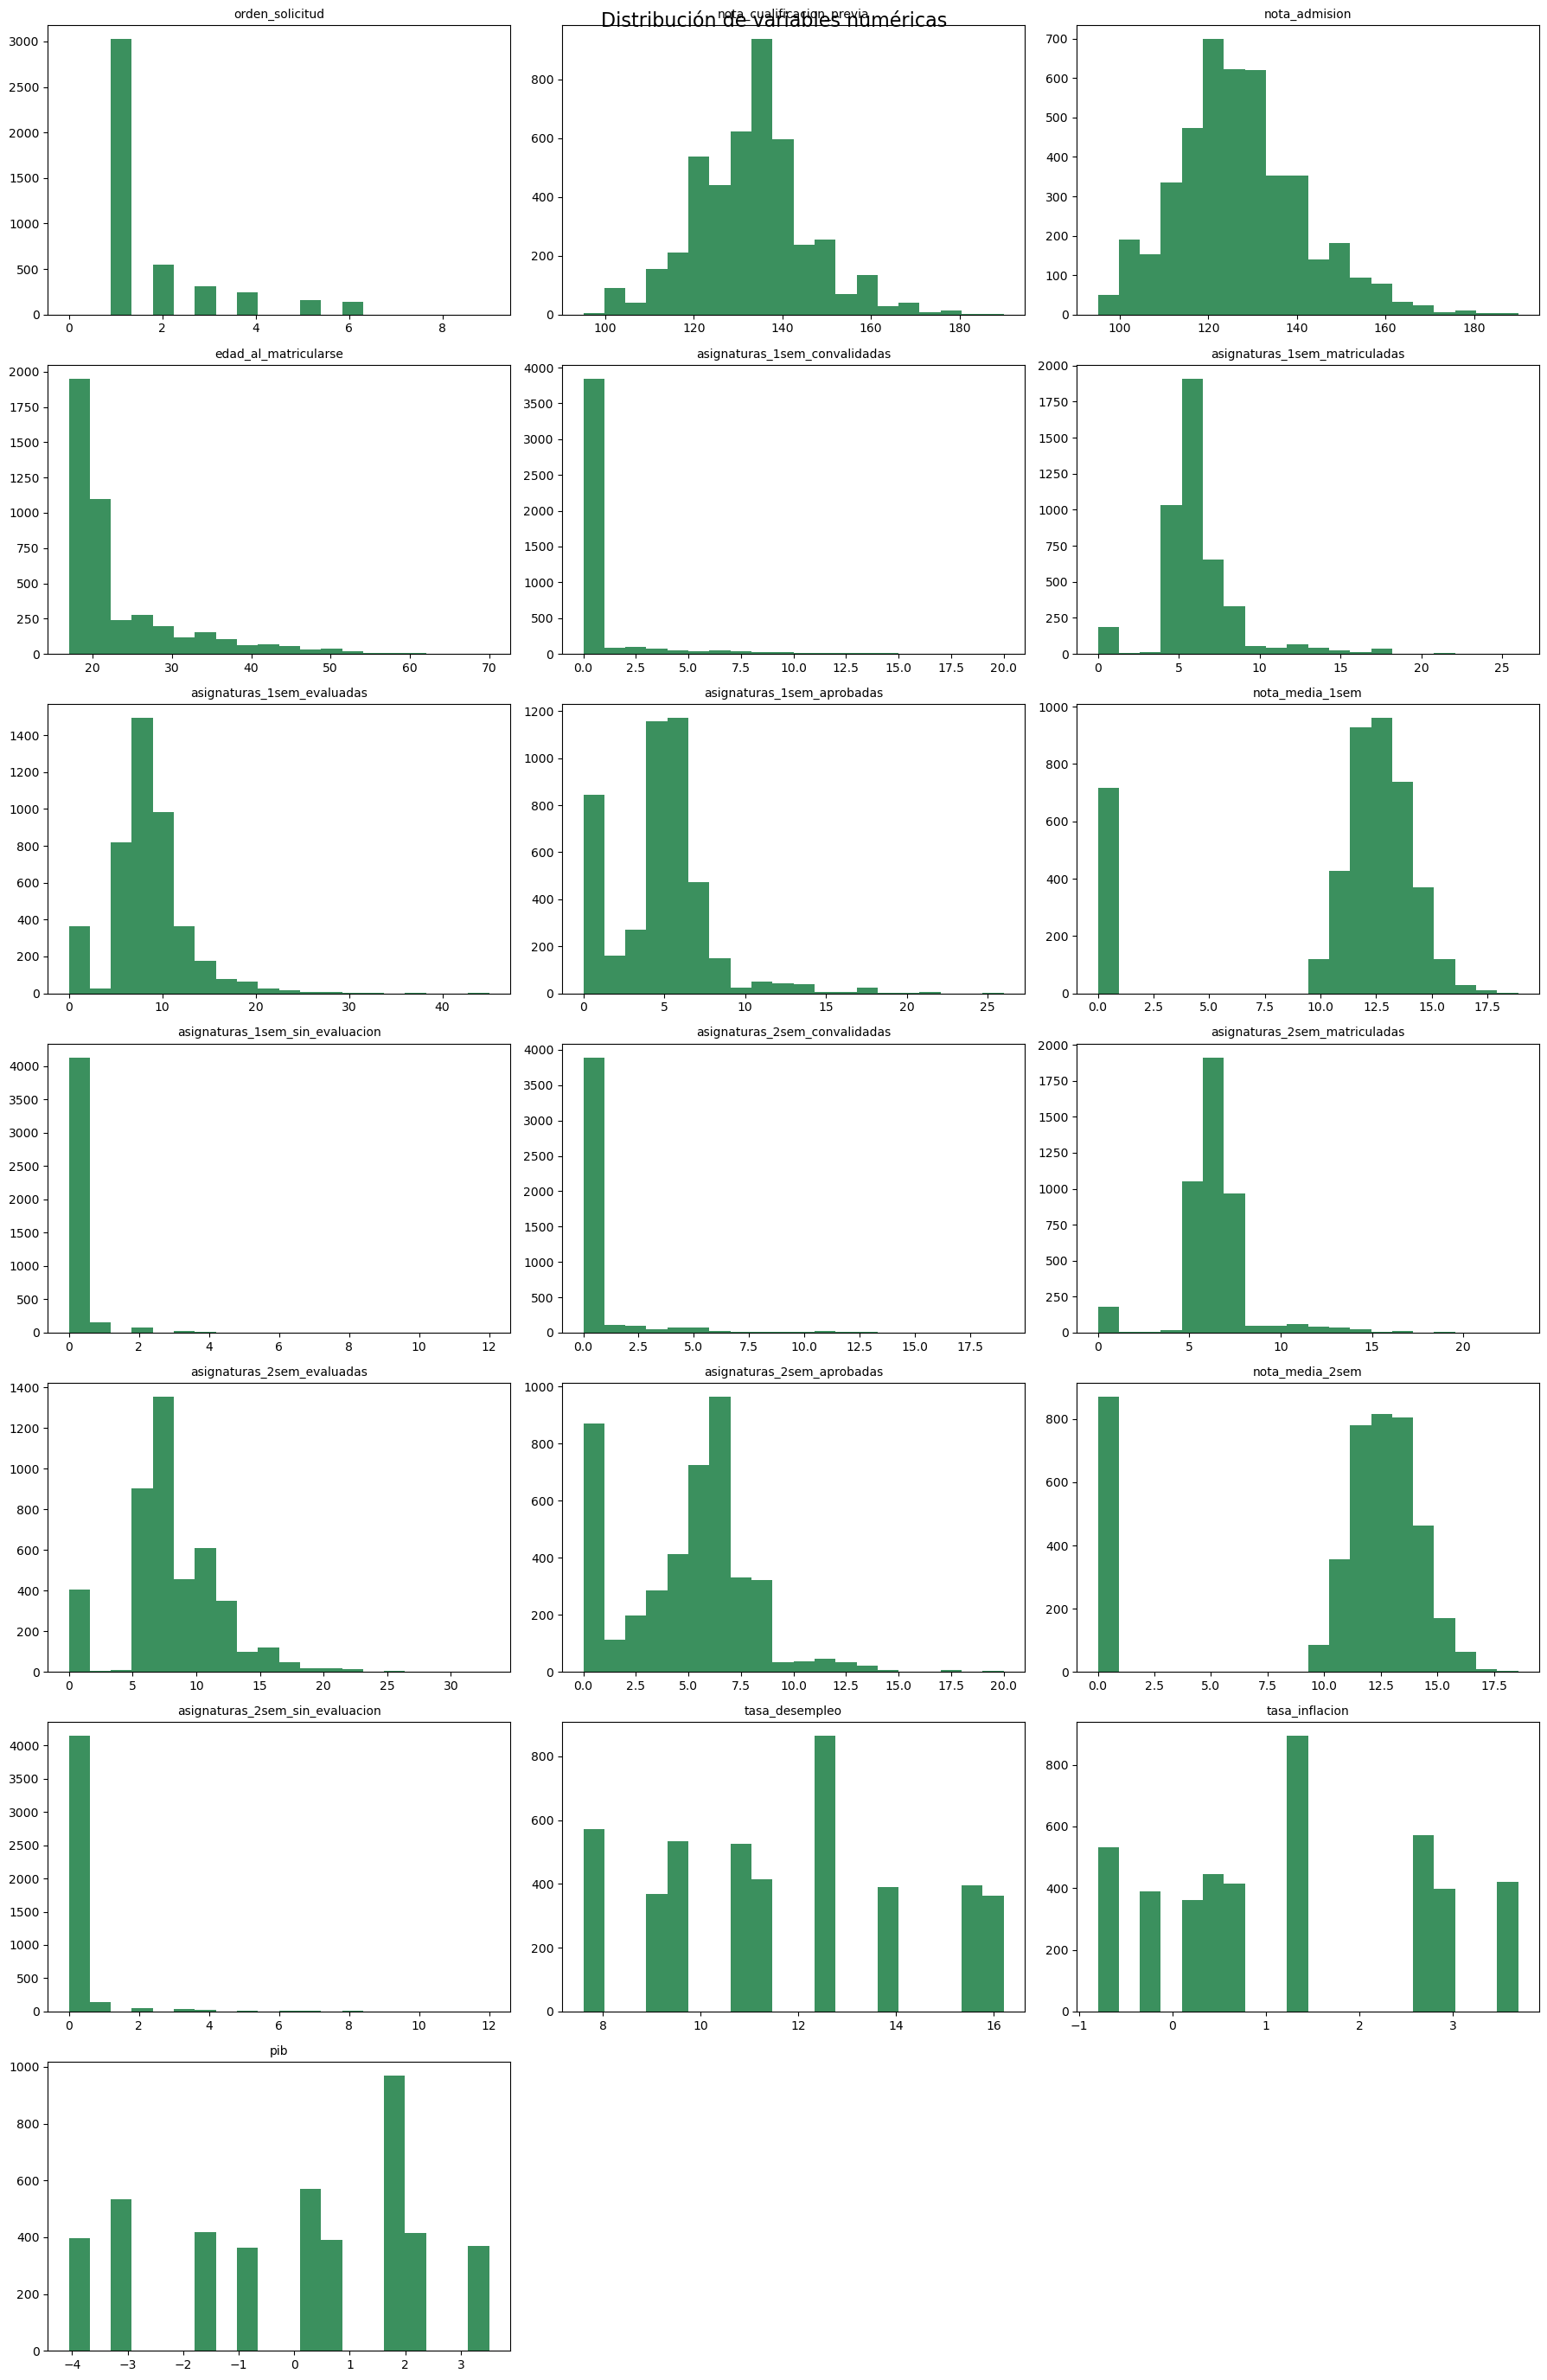

In [78]:
# Distribución variables numéricas

n_cols = 3
n_rows = math.ceil(len(col_num) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(col_num):
    axes[i].hist(df[col], bins=20, color="#3b905e")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Distribución de variables numéricas", fontsize=16)
plt.tight_layout()
plt.show()

**` Correlación entre variables numéricas`**

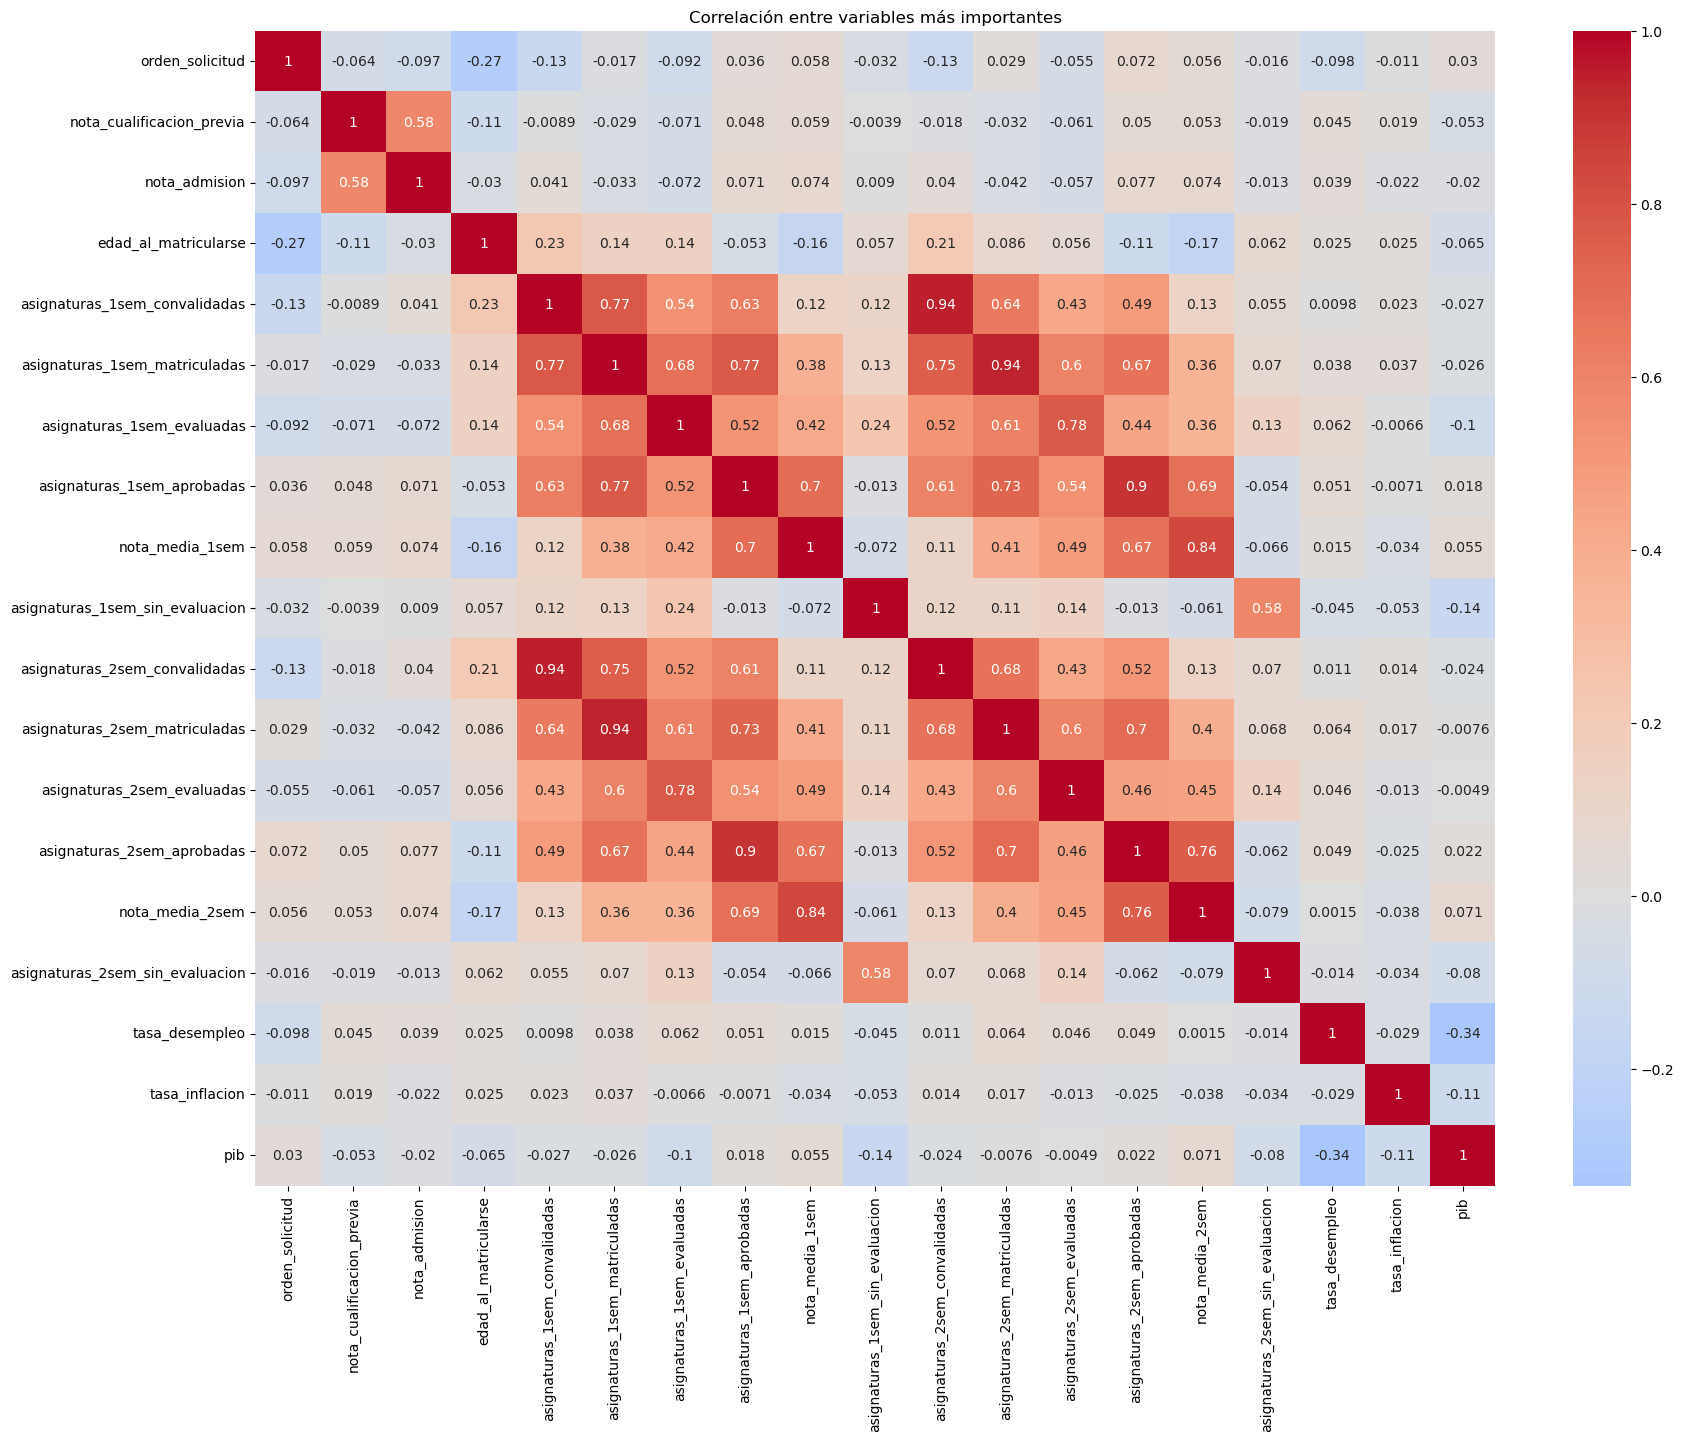

In [79]:
plt.figure(figsize=(20,15))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", center=0)
plt.title("Correlación entre variables más importantes")
plt.show()

En base a la correlación entre las variables se puede deducir que las variables socioeconómicas tienen bastante poco impacto en

### 2.2. Selección de datos

Para la creación de este modelo, se van a comparar distintas selecciones de variables con el objetivo de analizar cuales son las características que más influyen en la estructura de los clusters y calidad del modelo. Para ello se tendrán en cuenta sobretodo variables socioeconómicas como aquellas relacionadas con el rendimeinto académico para analizar su influencia en los clusters.

In [80]:
cols_completas_academicas = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "asignaturas_1sem_matriculadas",
    "asignaturas_1sem_evaluadas",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_1sem_sin_evaluacion",
    "asignaturas_2sem_matriculadas",
    "asignaturas_2sem_evaluadas",
    "asignaturas_2sem_aprobadas",
    "nota_media_2sem",
    "asignaturas_2sem_sin_evaluacion"
]

cols_academicas_factores_sociales = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "asignaturas_1sem_matriculadas",
    "asignaturas_1sem_evaluadas",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_1sem_sin_evaluacion",
    "asignaturas_2sem_matriculadas",
    "asignaturas_2sem_evaluadas",
    "asignaturas_2sem_aprobadas",
    "nota_media_2sem",
    "asignaturas_2sem_sin_evaluacion",
    'tasa_desempleo','tasa_inflacion', 'pib']

X1 = df[cols_completas_academicas].copy()
X2 = df[cols_academicas_factores_sociales].copy()

Además, aparte del estudio que se realizará con esas selecciones de variables, teniendo en cuenta la ,atriz de correlacioens del punto anterior, hacemos un último posible modelo. Para ellos, observamos las correlaciones que existen entre las variables:    
- Vemos que aquellas variables que pertenecen al primer semestre tienen una gran correlación entre ellas y que por lo tanto, 'miden prácticamente lo mismo' pudiendo generar problemas en el modelo, pues KMeans debido a que distorsiona distancias puede hacer que estas variables oesaen más empeorando la calidad de los clusters. Como consecuencia, he decidido utilizar únicamente las variables nota_media_1sem     
- En las variables del segunda semestre, podemos observar un comportamiento similar a las del primero, por lo tanto, he decidido tratarlas de la misma manera y quedarme únicamente con nota_media_2sem     
- En cuanto a las variables macroeconómicas, las correlaciones que se observan son bajas, asi que se deciden no mantenerlas. Esto se debe a que tienen una correlación tan baja que podrían añadir ruido y además, no diferenciarán casi a los individuos.
- Por último, lo que respecta a las variables categóricas he decidido mantener aquellas que contienen información relevante sobre el estudiante, como son las variables socioeconómicas y adminnistrativas.     
Sin embargo, se debe de tener en cuenta que dado que este tipo de variables no se pueden utilizar directamente en algoritmos basados en distancias, como es nuestro caso, pues no existe una relación numérica natural entre sus categorías. Debido a esto se ha decidido aplicar una transformación mediante one-hot que permite representar cada una de las categorías con una variable binaria sin introducir relaciones artificiales entre ellas.   
Además, se ha evitado incluir variables categóricas con un número muy elevado de categorias o con escasa relevancia interpretativa, pues estas podrían introducir ruido al modelo y dificultar la interpretación de patrones claros.
De este modo, se busca lograr un equilibrio entre la riqueza descriptiva del conjunto de variables y la calidad del agrupamiento obtenido.


In [81]:
# Las que respectan a los padres no las incluyo porque tienen muchas categorías, pudiendo hacer explotar en one-hot, 
# además son muy dispersas y añadirían poca señal en el clustering pudiendo meter mucho ruido. 
# Sin embargo, se utilizarán después con el fin de hacer un análisis socieconómico profundo.

columnas_simplificadas = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "nota_media_1sem",
    "nota_media_2sem",
    # Baja dimensionalidad, mucho significado (socioeconómicas)
    "becado", 
    "deudor",
    "matricula_al_dia",
    "desplazado"]
X3 = df[columnas_simplificadas]

## 3. Funciones para crear el modelo

### 3.1. Preprocesado del df

In [82]:
def preprocess_df(df: pd.DataFrame):
    df = df.copy()

    # Columnas numéricas y categóricas
    numeric_cols = df.select_dtypes(include=["number"]).columns
    categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

    # Estandarizar numéricas
    df_num = df[numeric_cols]
    df_num_std = (df_num - df_num.mean()) / df_num.std(ddof=1)

    if len(categorical_cols)>0:
        # One-hot encoding categóricas
        df_cat = pd.get_dummies(df[categorical_cols], drop_first=False).astype(int)

        # Juntar todo
        df_processed = pd.concat([df_num_std, df_cat], axis=1)
    else:
        df_processed = df_num_std.copy()

    return df_processed

### 3.2. PCA

Creo la función de PCA que se utilizará más adelante para disminuir la dimensionalidad del modelo

In [83]:
def PCA(X:pd.DataFrame, umbral = 0.9):
    
    X = np.asarray(X, dtype=float)

    mean = X.mean(axis=0)
    std = X.std(axis=0, ddof=1)
    X_std = (X-mean)/std

    SIGMA = (X_std.T @ X_std)/(X_std.shape[0]-1)

    eigenvalues, eigenvectors = np.linalg.eigh(SIGMA)

    index = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[index]
    eigenvectors = eigenvectors[:, index]

    PVE = eigenvalues/eigenvalues.sum()
    PVE_acumulada = np.cumsum(PVE)
    n_componentes = np.argmax(PVE_acumulada >= umbral) + 1
    
    PHI = eigenvectors[:,:n_componentes]
    Z = X_std @ PHI

    return PVE, PHI, n_componentes, Z, mean, std


### 3.3. Función del modelo

Utilizaremos el modelo K-Means de clustering 

In [84]:
def distance (x1, x2):
    """Función que calcula la distancia euclidia entre dos vectores"""
    x1 = np.asarray(x1, dtype=float)
    x2 = np.asarray(x2, dtype=float)
    return np.sqrt(np.sum((x1-x2)**2))

In [85]:
def KMeans (K:int, X, iteraciones=100, tol=1e-6):

    X = np.asarray(X, dtype=float)

    indices = np.random.choice(len(X), size=K, replace=False)    
    centroids = X[indices]

    for _ in range(iteraciones):
        
        # Se le asigna a cada punto al centroide más cercano
        distancias = np.linalg.norm(X[:,None]-centroids, axis=2)
        clusters = np.argmin(distancias, axis=1)
        

        # Se recalculan los nuevos centroides
        centroids_new = []
        for k in range (K):
            data = X[clusters == k]

            if len(data) == 0:
                centroids_new.append(X[np.random.randint(len(X))])
            else:
                centroids_new.append(data.mean(axis=0))

        # Se observa si son lo suficientemente parecidos como para finalizar 
        centroids_new = np.array(centroids_new)
        if np.allclose(centroids, centroids_new, atol=tol):
            break

        centroids=centroids_new 
            
    return clusters, centroids



### 3.4. Selección del parámetro K

**Método del codo**

In [86]:
def elbow(n_centroids:list, X):

    X = np.asarray(X, dtype=float)

    WCSS_clusters = {}
    for k in n_centroids:

        clusters, centroids = KMeans(k, X)
        distancias = X - centroids[clusters]
        WCSS = np.sum(distancias**2)

        WCSS_clusters[k] = WCSS
    
    return WCSS_clusters

**Método de la silueta**

In [87]:
def matriz_distancias(X):
    X = np.asarray(X, dtype=float)
    D = np.linalg.norm(X[:, None] - X[None, :], axis=2)
    return D

def silhouette_scores(D, clusters):
    clusters = np.asarray(clusters)
    n = len(clusters)

    clusters_unicos = np.unique(clusters)
    S = []

    for i in range(n):
        cluster_i = clusters[i]

        indices_mismo = np.where(clusters == cluster_i)[0]
        indices_mismo = indices_mismo[indices_mismo != i]

        if len(indices_mismo) == 0:
            a_i = 0
        else:
            a_i = np.mean(D[i, indices_mismo])

        b_i = []

        for cluster in clusters_unicos:
            if cluster != cluster_i:
                indices_otro = np.where(clusters == cluster)[0]

                if len(indices_otro) > 0:
                    b_i.append(np.mean(D[i, indices_otro]))

        if len(b_i) == 0:
            s_i = 0
        else:
            b_i = min(b_i)

            if max(a_i, b_i) == 0:
                s_i = 0
            else:
                s_i = (b_i - a_i) / max(a_i, b_i)

        S.append(s_i)

    return np.asarray(S), np.mean(S)

def silhouette(n_centroids, X):
    X = np.asarray(X, dtype=float)


    D = matriz_distancias(X)

    S = {}

    for k in n_centroids:
        clusters, centroids = KMeans(k, X)
        s_values, media_s = silhouette_scores(D, clusters)
        S[k] = media_s

    return S

### 3.5. Graficar resultados

In [88]:
def graficos_resultados(resultados):

    n_modelos = len(resultados)

    fig, axes = plt.subplots (n_modelos, 2, figsize=(12,4*n_modelos))

    for i, res in enumerate(resultados):

        nombre = res["nombre"]
        WCSS = res["WCSS"]
        SIL = res["SIL"]

        # Gráfico del codo
        axes[i, 0].plot(list(WCSS.keys()), list(WCSS.values()), marker="o")
        axes[i, 0].set_title(f"{nombre} - Método del codo")
        axes[i, 0].set_xlabel("K")
        axes[i, 0].set_ylabel("WCSS")
        axes[i, 0].grid(True)
        
        # Gráfico de la silueta
        axes[i, 1].plot(list(SIL.keys()), list(SIL.values()), marker="o")
        axes[i, 1].set_title(f"{nombre} - Método de la silueta")
        axes[i, 1].set_xlabel("K")
        axes[i, 1].set_ylabel("Media Silhouette")
        axes[i, 1].grid(True)

    plt.tight_layout()
    plt.show()

## 4. Modelo

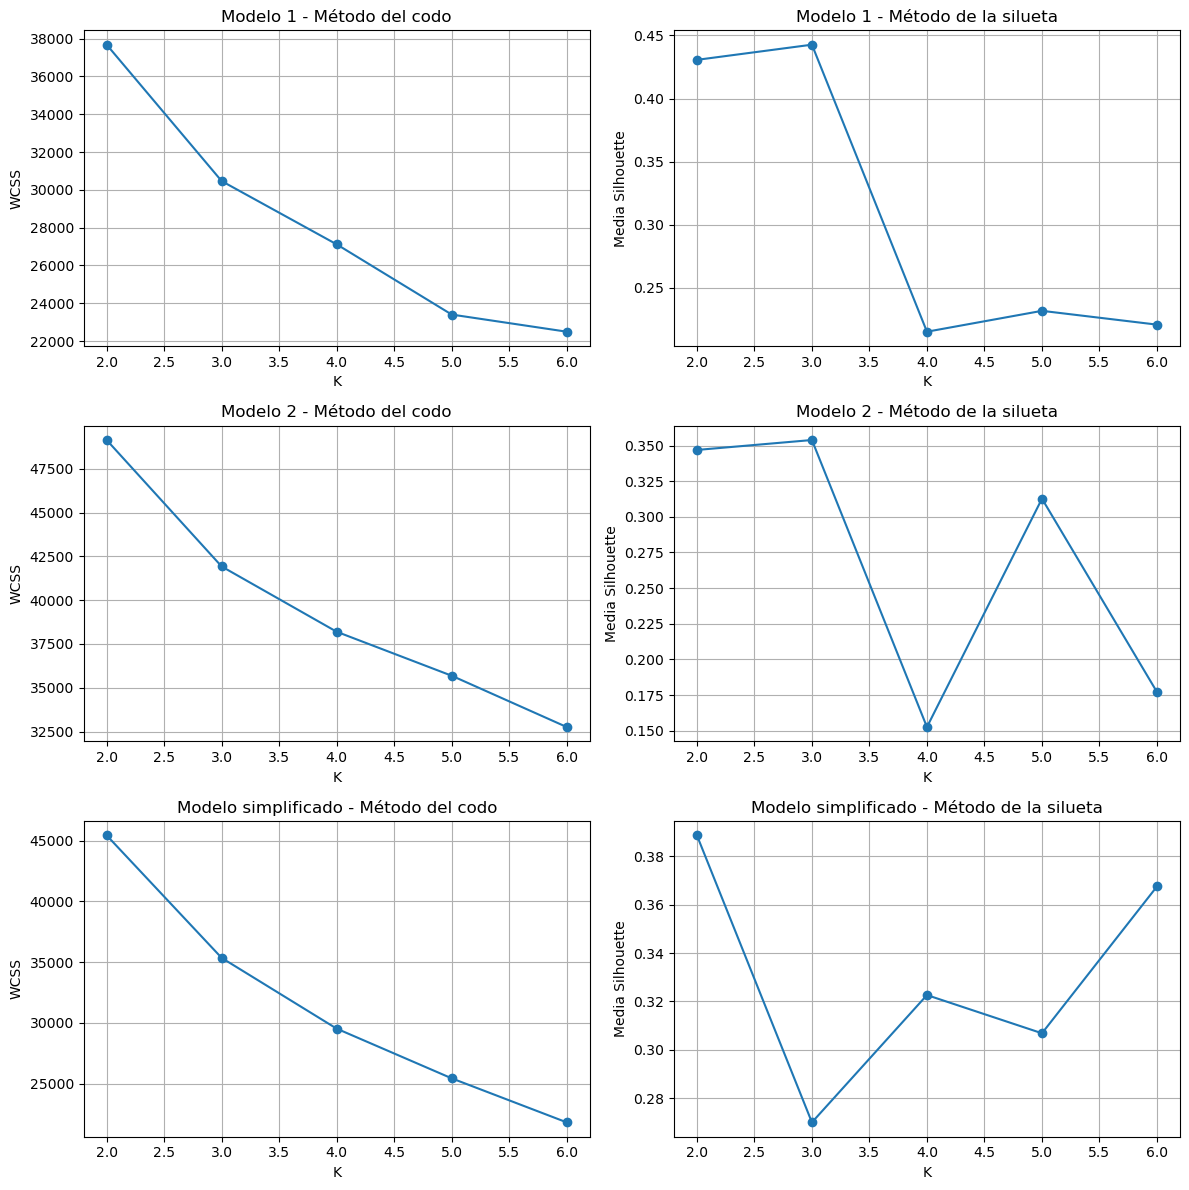

In [89]:
n_centroids = [2,3,4,5,6]

resultados = []

for X, nombre in [(X1, "Modelo 1"), (X2, "Modelo 2"), 
                  (X3, "Modelo simplificado")]:

    X_procesado = preprocess_df(X)
    PVE, PHI, n_componentes, X_PCA, mean, std = PCA(X_procesado)
    

    # Codo:
    WCSS = elbow(n_centroids, X_PCA)
    # Silueta
    SIL = silhouette(n_centroids, X_PCA)

    resultados.append({"nombre": nombre,
                       "WCSS": WCSS,
                       "SIL": SIL})

graficos_resultados(resultados)


Se compararon distintas configuraciones de variables para evaluar su impacto en la estructura de los clusters. El modelo basado en el segundo conjunto de variables mostró una baja calidad de agrupamiento, con valores reducidos del índice de silueta y ausencia de un codo claro, lo que sugiere una estructura poco definida.

Por el contrario, los modelos 1 y 3 presentan valores de silueta más elevados, indicando una mejor separación entre clusters. En particular, el modelo 3 muestra los mejores resultados, con valores de silueta superiores a 0.4 y un codo claro en torno a k = 3–4.

Por tanto, se selecciona el modelo 3 como base para el análisis final, al ofrecer el mejor compromiso entre calidad de agrupamiento e interpretabilidad.

Aunque el modelo basado en variables académicas completas presenta valores ligeramente superiores del índice de silueta, este incluye un alto grado de redundancia entre variables, tal y como se observa en la matriz de correlación. 

Esta redundancia puede distorsionar las distancias utilizadas por KMeans, otorgando un peso excesivo a determinadas dimensiones y generando una aparente mejora en la separación de los clusters.

Por este motivo, se opta por un modelo más parsimonioso basado en un subconjunto reducido de variables, que permite obtener agrupamientos más interpretables y coherentes con el problema, manteniendo además una calidad de clustering adecuada.

## 5. Modelo final y conclusiones

Una vez ya hemos sacado las conclusiones pertinentes, nos quedamos con el modelo simplificado y k=3

Aunque el índice de silueta alcanza su valor máximo para k = 6, se opta por seleccionar k = 3 como número final de clusters. Esta decisión se basa en criterios de interpretabilidad, ya que un número reducido de clusters permite identificar perfiles de estudiantes más claros y fácilmente analizables. Además, valores de k más elevados tienden a fragmentar excesivamente los datos, generando grupos más difíciles de interpretar desde un punto de vista aplicado.

Aunque algunos modelos que incluyen un mayor número de variables académicas presentan valores ligeramente superiores del índice de silueta, estos incorporan un alto grado de redundancia entre variables, tal y como se observa en la matriz de correlación. 

Esta redundancia puede distorsionar las distancias empleadas por KMeans, generando una mejora artificial en la separación de los clusters.

Por este motivo, se selecciona como modelo final el conjunto de variables simplificado, que combina información académica, características de entrada y variables socioeconómicas relevantes. Este modelo permite obtener agrupamientos más robustos e interpretables, manteniendo una calidad de clustering adecuada.

### 5.1. Creación del modelo final con k=3

In [90]:
columnas_finales = [
    "edad_al_matricularse",
    "nota_admision",
    "nota_cualificacion_previa",
    "nota_media_1sem",
    "nota_media_2sem",
    # Baja dimensionalidad, mucho significado (socioeconómicas)
    "becado", 
    "deudor",
    "matricula_al_dia",
    "desplazado"]

X_final = df[columnas_finales].copy()
X_final_procesado = preprocess_df(X_final)

PVE, PHI, n_componentes, X_PCA, mean, std = PCA(X_procesado)
    
k_final = 3
clusters_final, centroides_final = KMeans(k_final, X_final_procesado)

df_clusters = df.copy()
df_clusters["cluster"] = clusters_final



Variable Importance

In [91]:
pesos = pd.DataFrame(PHI, index=X_final_procesado.columns, columns=[f"PC{i+1}" for i in range(n_componentes)])
print(pesos["PC1"].sort_values(ascending=False))

matricula_al_dia_si          0.410517
deudor_no                    0.346229
nota_media_2sem              0.300099
nota_media_1sem              0.277740
becado_si                    0.234593
desplazado_si                0.204355
nota_cualificacion_previa    0.078856
nota_admision                0.064778
desplazado_no               -0.204355
edad_al_matricularse        -0.228032
becado_no                   -0.234593
deudor_si                   -0.346229
matricula_al_dia_no         -0.410517
Name: PC1, dtype: float64


Las componentes principales están dominadas por variables de rendimiento académico, especialmente la nota media del primer semestre, lo que refuerza la idea de que el desempeño inicial es el principal factor diferenciador entre perfiles.

Estabilidad de los clusters

In [92]:
scores = []

for i in range(5):

    clusters_temp, _ = KMeans(3, X_final_procesado)
    _, score = silhouette_scores(matriz_distancias(X_final_procesado), clusters_temp)
    scores.append(score)

print(f"Silhoutte media: {np.mean(scores)}")
print(f"Desviación: {np.std(scores)}")

Silhoutte media: 0.2326524891363953
Desviación: 0.03831202988770289


Se ha evaluado la estabilidad del modelo repitiendo el proceso de clustering varias veces. Los resultados muestran una variabilidad baja en el índice de silueta, lo que sugiere que los clusters obtenidos son robustos.

### 5.2 Análisis del modelo k=3

#### 5.2.1. Tamaño de los clusters

In [93]:
tam = df_clusters["cluster"].value_counts().sort_index()
porcentaje = df_clusters["cluster"].value_counts(normalize=True).sort_index()*100
print(f"El porcentaje de cada uno de los clusters con respecto al total es:\n{porcentaje}\nDonde cada cluster contiene la siguiente cantidad de muestras:\n{tam} ")
print("Se puede observar claramente que hay un grupo muy potente con casi la mitad de los datos.")

El porcentaje de cada uno de los clusters con respecto al total es:
cluster
0    47.739602
1    33.250452
2    19.009946
Name: proportion, dtype: float64
Donde cada cluster contiene la siguiente cantidad de muestras:
cluster
0    2112
1    1471
2     841
Name: count, dtype: int64 
Se puede observar claramente que hay un grupo muy potente con casi la mitad de los datos.


#### 5.2.2. Medias de las variables numéricas

In [94]:
variables_a_analizar = ["edad_al_matricularse",
                        "nota_admision",
                        "nota_cualificacion_previa",
                        "nota_media_1sem",
                        "nota_media_2sem",
                        "asignaturas_1sem_aprobadas",
                        "asignaturas_2sem_aprobadas"]
medias_por_cluster = df_clusters.groupby("cluster")[variables_a_analizar].mean()
print(f"A continuación, se muestran las medias de las variables numéricas del dataset en cada uno de los clusters:\n{medias_por_cluster}")

A continuación, se muestran las medias de las variables numéricas del dataset en cada uno de los clusters:
         edad_al_matricularse  nota_admision  nota_cualificacion_previa  \
cluster                                                                   
0                   23.157670     119.049716                 125.088778   
1                   21.868117     138.836642                 143.699116   
2                   25.978597     126.146849                 132.119382   

         nota_media_1sem  nota_media_2sem  asignaturas_1sem_aprobadas  \
cluster                                                                 
0              12.393219        12.257040                    5.553030   
1              13.178009        12.924764                    5.972128   
2               1.802217         0.427150                    0.367420   

         asignaturas_2sem_aprobadas  
cluster                              
0                          5.268939  
1                          5.738953  

#### 5.2.4. Diferencias de las variables numéricas con respecto a la media global

In [95]:
media_global = df_clusters[variables_a_analizar].mean()
print(f"A continuación se muestran las diferencias que existen en las medias de los distintos clusters con respecto a la media gloabal del dataset sin agrupar:\n{media_global-medias_por_cluster}")

A continuación se muestran las diferencias que existen en las medias de los distintos clusters con respecto a la media gloabal del dataset sin agrupar:
         edad_al_matricularse  nota_admision  nota_cualificacion_previa  \
cluster                                                                   
0                    0.107474       7.928403                   7.524535   
1                    1.397028     -11.858522                 -11.085803   
2                   -2.713452       0.831270                   0.493932   

         nota_media_1sem  nota_media_2sem  asignaturas_1sem_aprobadas  \
cluster                                                                 
0              -1.752398        -2.026834                   -0.846430   
1              -2.537187        -2.694559                   -1.265527   
2               8.838605         9.803056                    4.339181   

         asignaturas_2sem_aprobadas  
cluster                              
0                         -0.8

#### 5.2.5. Variables categóricas por cluster

In [96]:
variables_a_analizar_categoricas = ["becado",
                                    "deudor",
                                    "matricula_al_dia",
                                    "desplazado",
                                    "genero",
                                    "objetivo"]

for col in variables_a_analizar_categoricas:
    print(col)
    print("-------------------------------")
    print("   Frecuencia")
    print("-------------------------------")
    print(pd.crosstab(df_clusters["cluster"], df_clusters[col]))
    print("-------------------------------")
    print("   Porcentaje")
    print("-------------------------------")
    print(pd.crosstab(df_clusters["cluster"], df_clusters[col], normalize="index")*100)

becado
-------------------------------
   Frecuencia
-------------------------------
becado     no   si
cluster           
0        1534  578
1        1033  438
2         758   83
-------------------------------
   Porcentaje
-------------------------------
becado          no         si
cluster                      
0        72.632576  27.367424
1        70.224337  29.775663
2        90.130797   9.869203
deudor
-------------------------------
   Frecuencia
-------------------------------
deudor     no   si
cluster           
0        1890  222
1        1351  120
2         680  161
-------------------------------
   Porcentaje
-------------------------------
deudor          no         si
cluster                      
0        89.488636  10.511364
1        91.842284   8.157716
2        80.856124  19.143876
matricula_al_dia
-------------------------------
   Frecuencia
-------------------------------
matricula_al_dia   no    si
cluster                    
0                 188  1924
1    

#### 5.2.6. Relación de los clusters con la variable objetivo

In [97]:
tabla_objetivo = pd.crosstab(df_clusters["cluster"], df["objetivo"], normalize="index")*100
print(tabla_objetivo.round(2))

objetivo  abandono  graduado  matriculado
cluster                                  
0            22.92     54.17        22.92
1            16.86     67.30        15.84
2            81.93      8.92         9.16


Con el objetivo de evaluar la utilidad de los clusters obtenidos, se analizó la distribución de la variable objetivo dentro de cada grupo.

Es importante destacar que dicha variable no fue utilizada en la construcción del modelo, por lo que cualquier patrón observado refleja asociaciones emergentes a partir de las características de los estudiantes.

Los resultados muestran diferencias muy marcadas entre clusters. En particular, uno de los grupos concentra una proporción significativamente elevada de estudiantes que abandonan los estudios, mientras que otro presenta una mayor proporción de graduados. Esto indica que el modelo de clustering ha sido capaz de capturar estructuras relevantes relacionadas con la trayectoria académica del alumnado.

Estos hallazgos refuerzan la validez del enfoque no supervisado aplicado, sugiriendo que las variables seleccionadas permiten identificar perfiles de estudiantes con comportamientos académicos claramente diferenciados.

#### 5.2.7. Infleuncia de los progenitores

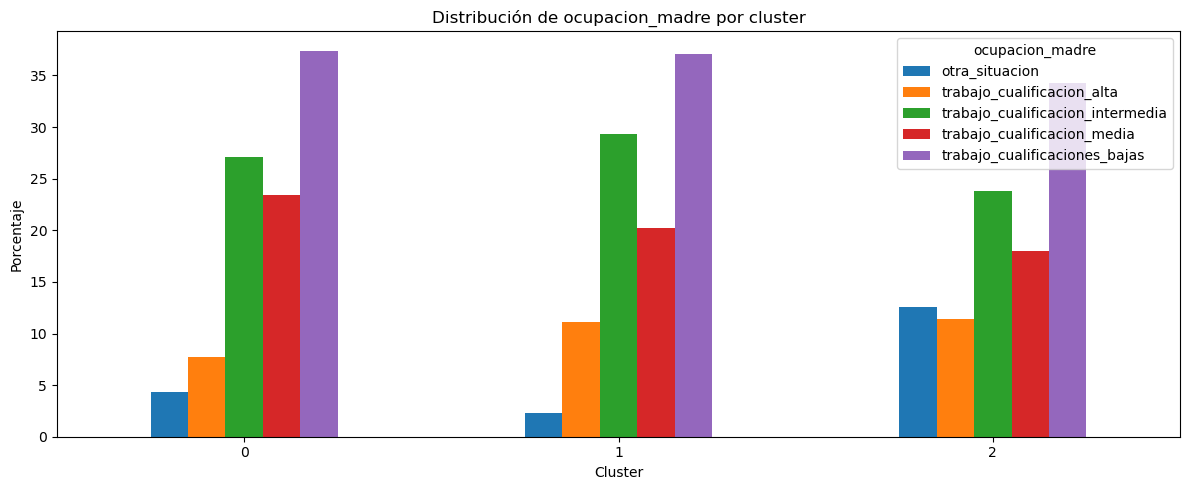

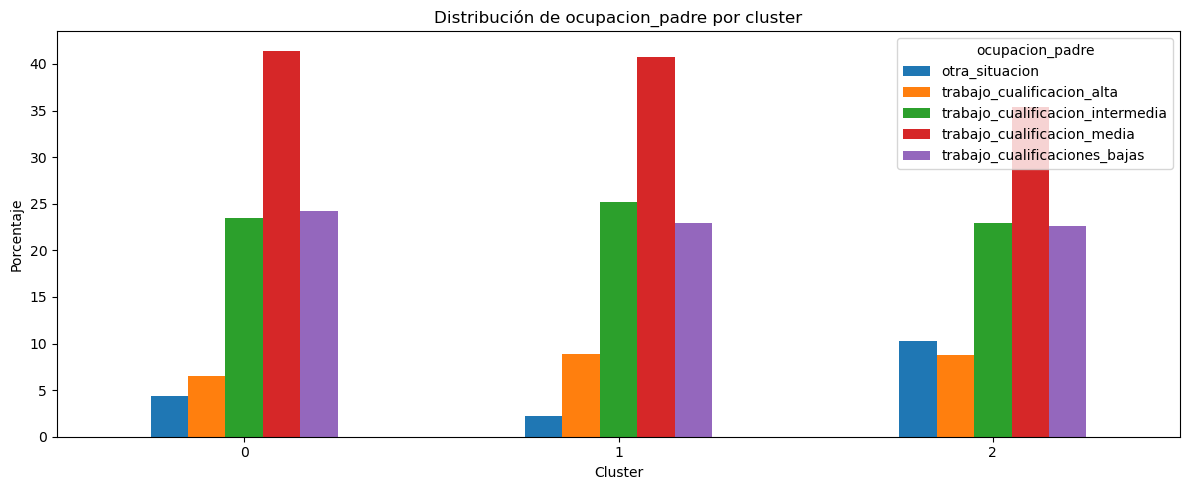

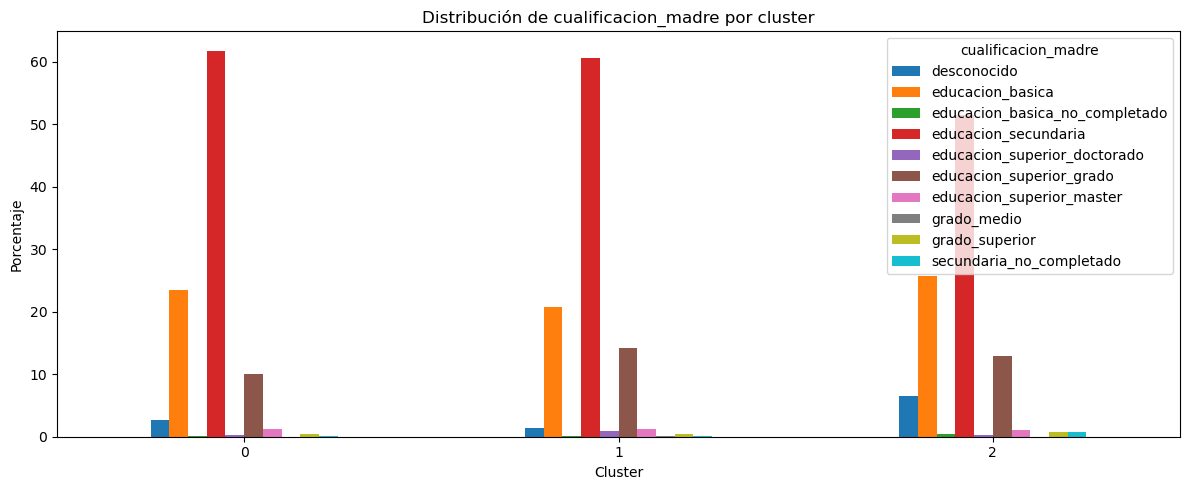

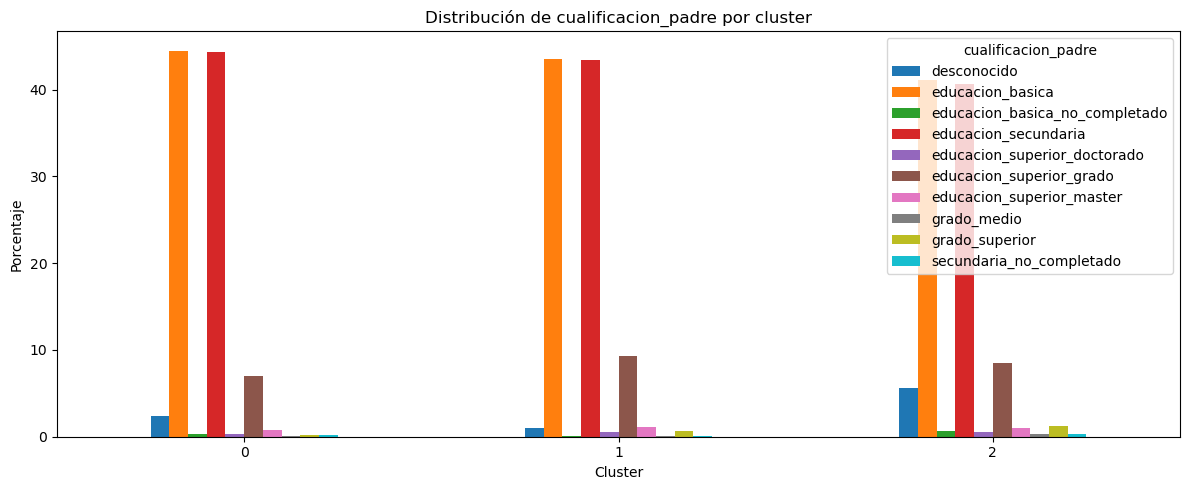

In [98]:
variables_padres = ["ocupacion_madre",
                    "ocupacion_padre",
                    "cualificacion_madre",
                    "cualificacion_padre"
                    ]

for col in variables_padres:

    tabla = pd.crosstab(df_clusters["cluster"], df_clusters[col], normalize="index")*100
    tabla.plot(kind="bar", figsize=(12,5))

    plt.title(f"Distribución de {col} por cluster")
    plt.xlabel("Cluster")
    plt.ylabel("Porcentaje")
    plt.legend(title=col)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


#### 5.2.8. GRÁFICOS

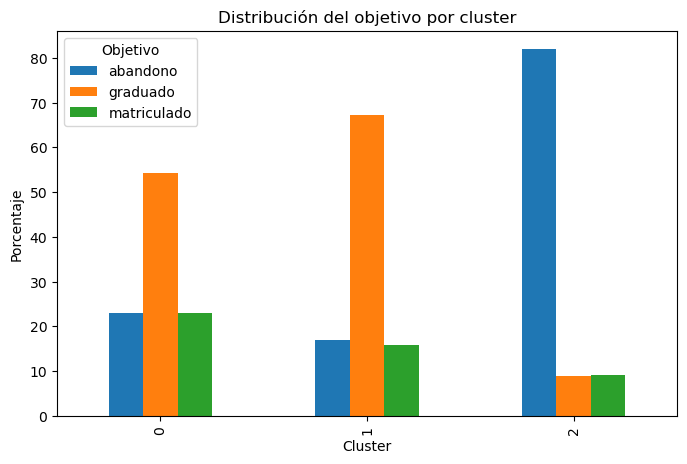

In [99]:
tabla_objetivo.plot(kind="bar", figsize=(8,5))
plt.title("Distribución del objetivo por cluster")
plt.xlabel("Cluster")
plt.ylabel("Porcentaje")
plt.legend(title="Objetivo")
plt.show()

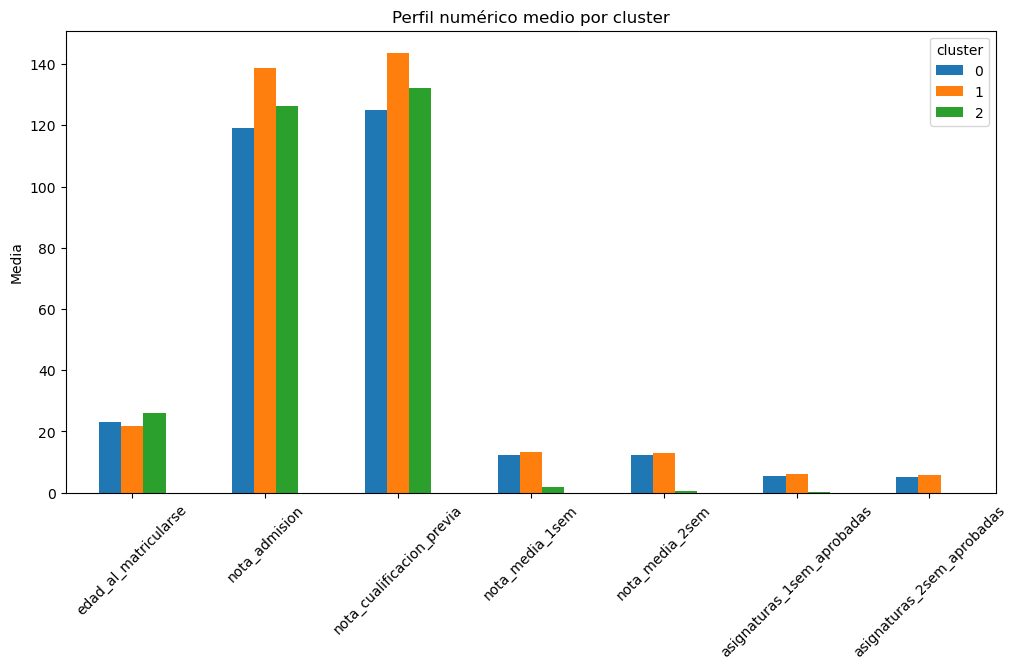

In [100]:
medias_por_cluster.T.plot(kind="bar", figsize=(12,6))
plt.title("Perfil numérico medio por cluster")
plt.ylabel("Media")
plt.xticks(rotation=45)
plt.show()

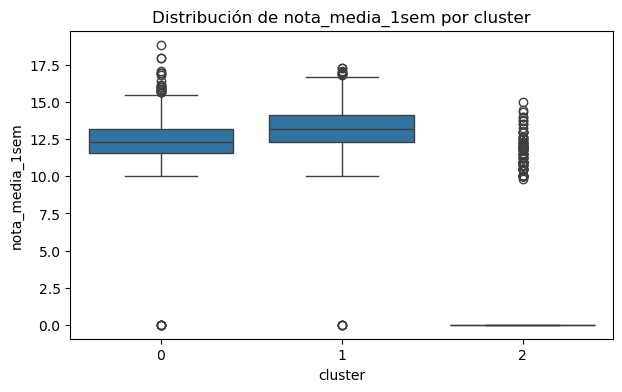

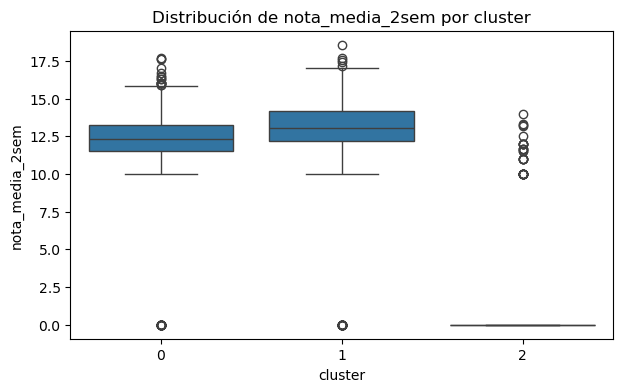

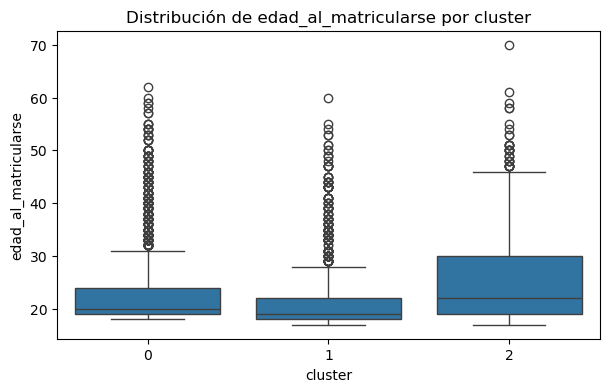

In [101]:
for col in ["nota_media_1sem", "nota_media_2sem", "edad_al_matricularse"]:
    plt.figure(figsize=(7,4))
    sns.boxplot(x="cluster", y=col, data=df_clusters)
    plt.title(f"Distribución de {col} por cluster")
    plt.show()

Aunque el índice de silueta alcanza valores más elevados para k = 6, se observa que este valor conduce a una fragmentación excesiva de los datos, dividiendo perfiles naturales en subgrupos difíciles de interpretar.

Por el contrario, la elección de k = 3 permite identificar tres perfiles claramente diferenciados de estudiantes: alto rendimiento, rendimiento intermedio y alto riesgo académico. Esta segmentación resulta más útil desde un punto de vista aplicado, facilitando la interpretación de los resultados y su posible utilización en contextos educativos.

Por tanto, se selecciona k = 3 como número final de clusters, priorizando la interpretabilidad y la utilidad del modelo frente a pequeñas mejoras en métricas cuantitativas.